**Import all neccessary libraries**

In [81]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Model saving
import joblib

# CatBoost
from catboost import CatBoostRegressor

# File management
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)

sns.set_style("whitegrid")

print("All libraries imported successfully")

All libraries imported successfully


In [82]:
import os
print("Current working directory:", os.getcwd())

Current working directory: C:\Users\HomePC


In [83]:
# # Define project directory
# BASE_DIR = Path.cwd().parent

# # Define dataset path
DATA_PATH = r"C:\Users\HomePC\used_car_valuation\data\car_prices.csv"
# MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Data loaded successfully")

Data loaded successfully


In [84]:
df.head()

,car_id,price,fuel type,gear type,Make,Model,Year of manufacture,Colour,Condition,Mileage,Engine Size,Selling Condition,Bought Condition,car,Trim,Drivetrain,Seats,Number of Cylinders,Horse Power,Registered city,Engine Size Original,Vehicle Age,Mileage per year,Make_Model
0,icwAaDOmX573WiRRnLFPT237,2812500,Petrol,Automatic,Toyota,Corolla,2004,Silver,Nigerian Used,251732.0,1800.0,Registered,Registered,Unknown,unknown,Unknown,NaN,NaN,NaN,Unknown,1800.0,22,11442.363636,ToyotaCorolla
1,ByZ3NlPy2x0arAIyrKazClUS,5000000,Petrol,Automatic,Acura,Mdx,2007,Green,Foreign Used,224589.0,3700.0,Imported,Imported,Suv,unknown,Unknown,NaN,NaN,NaN,Unknown,3700.0,19,11820.473684,AcuraMdx
2,2zG6Mh3kwyoTvWoeKHkV1oFH,7592000,Petrol,Automatic,Acura,Tl,2012,White,Foreign Used,111334.0,3500.0,Imported,Imported,Sedan,SH-AWD Automatic Tech Package,All Wheel,5.0,6.0,309.0,Unknown,3500.0,14,7952.428571,AcuraTl
3,7APLHOPlI93qsYK0ST4D4wB2,9880000,Petrol,Automatic,Land Rover,Range Rover,2012,Gray,Nigerian Used,72682.0,4000.0,Registered,Imported,Suv,unknown,Unknown,NaN,NaN,NaN,Unknown,4000.0,14,5191.571429,Land RoverRange Rover
4,zIrIDPJLd46eRQf9JFacc0e,4160000,Petrol,Automatic,Ford,Edge,2013,Gray,Nigerian Used,92118.0,3500.0,Registered,Registered,Suv,unknown,Unknown,NaN,NaN,NaN,Lagos,3500.0,13,7086.000000,FordEdge


In [85]:
# Data shape
print("\nDataset shape:", df.shape) 


Dataset shape: (3120, 24)


In [86]:
# Data information
print("\nDataset information:", df.info)


Dataset information: <bound method DataFrame.info of                         car_id    price fuel type  gear type           Make  \
0     icwAaDOmX573WiRRnLFPT237  2812500    Petrol  Automatic         Toyota   
1     ByZ3NlPy2x0arAIyrKazClUS  5000000    Petrol  Automatic          Acura   
2     2zG6Mh3kwyoTvWoeKHkV1oFH  7592000    Petrol  Automatic          Acura   
3     7APLHOPlI93qsYK0ST4D4wB2  9880000    Petrol  Automatic     Land Rover   
4      zIrIDPJLd46eRQf9JFacc0e  4160000    Petrol  Automatic           Ford   
...                        ...      ...       ...        ...            ...   
3115  C4Ly76wwazrtbYRAWkTnv2Q5  1924000    Petrol  Automatic         Toyota   
3116  jPA7XlJJxdwpZStlurumw59q  1890000    Petrol  Automatic  Mercedes-Benz   
3117  g5szhuHeXu2djH1Z2be22G7E  1155000    Petrol  Automatic         Toyota   
3118  mdZMNQK7Zez0cSS67Q9Quhzr  1260000    Petrol  Automatic         Toyota   
3119  fSUvulLwnXYlc1muFsrjrsAR  1872000    Petrol  Automatic          Honda  

**Check missing values**

In [87]:
missing_values = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by="Percentage",
    ascending=False
)

missing_values
                   

    

,Missing values,Percentage
Horse Power,2485,79.647436
Seats,2458,78.782051
Number of Cylinders,2425,77.724359
Engine Size,134,4.294872
Engine Size Original,134,4.294872
Mileage,51,1.634615
Mileage per year,51,1.634615
car_id,0,0.000000
Colour,0,0.000000
Year of manufacture,0,0.000000


**Statistical analysis**

In [88]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,3120.0,4.492929e+06,4.378738e+06,550000.000000,2.310000e+06,3.328000e+06,4.992000e+06,6.240000e+07
Year of manufacture,3120.0,2.008111e+03,4.215790e+00,1979.000000,2.005000e+03,2.008000e+03,2.011000e+03,2.022000e+03
Mileage,3069.0,1.945201e+05,1.365584e+05,1.000000,1.187300e+05,1.759680e+05,2.453280e+05,2.456318e+06
Engine Size,2986.0,2.784313e+03,8.612208e+02,180.000000,2.000000e+03,2.500000e+03,3.500000e+03,6.300000e+03
Seats,662.0,5.288520e+00,8.157793e-01,2.000000,5.000000e+00,5.000000e+00,5.000000e+00,8.000000e+00
Number of Cylinders,695.0,5.133813e+00,1.194702e+00,4.000000,4.000000e+00,6.000000e+00,6.000000e+00,8.000000e+00
Horse Power,635.0,2.070252e+02,7.028284e+01,83.000000,1.580000e+02,2.010000e+02,2.680000e+02,5.850000e+02
Engine Size Original,2986.0,2.784313e+03,8.612208e+02,180.000000,2.000000e+03,2.500000e+03,3.500000e+03,6.300000e+03
Vehicle Age,3120.0,1.788910e+01,4.215790e+00,4.000000,1.500000e+01,1.800000e+01,2.100000e+01,4.700000e+01
Mileage per year,3069.0,1.085542e+04,7.104140e+03,0.035714,6.946429e+03,9.783737e+03,1.333227e+04,1.611209e+05


**Check duplicate records**

In [89]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate car IDs:", df["car_id"].duplicated().sum())

print("Unique car IDs:", df["car_id"].nunique())

Duplicate rows: 0
Duplicate car IDs: 0
Unique car IDs: 3120


**Data cleaning**

In [90]:
# create a clean copy of the original dataset
df_clean = df.drop_duplicates().copy()

# reset index
df_clean.reset_index(drop=True, inplace=True)

# check results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("Remaining duplicate rows:", df_clean.duplicated().sum())
print("Remaining duplicate car IDs:", df_clean["car_id"].duplicated().sum())


Original dataset shape: (3120, 24)
Cleaned dataset shape: (3120, 24)
Remaining duplicate rows: 0
Remaining duplicate car IDs: 0


**Save the cleaned dataset**

In [91]:
CLEAN_DATA_PATH = r"C:\Users\HomePC\used_car_valuation\data\car_prices.csv"
df_clean.to_csv(CLEAN_DATA_PATH, index=False)
print("cleaned dataset saved successful!")

cleaned dataset saved successful!


**Exporatory data analysis**

In [92]:
print("Price statistics")
print(df_clean["price"].describe())


Price statistics
count    3.120000e+03
mean     4.492929e+06
std      4.378738e+06
min      5.500000e+05
25%      2.310000e+06
50%      3.328000e+06
75%      4.992000e+06
max      6.240000e+07
Name: price, dtype: float64


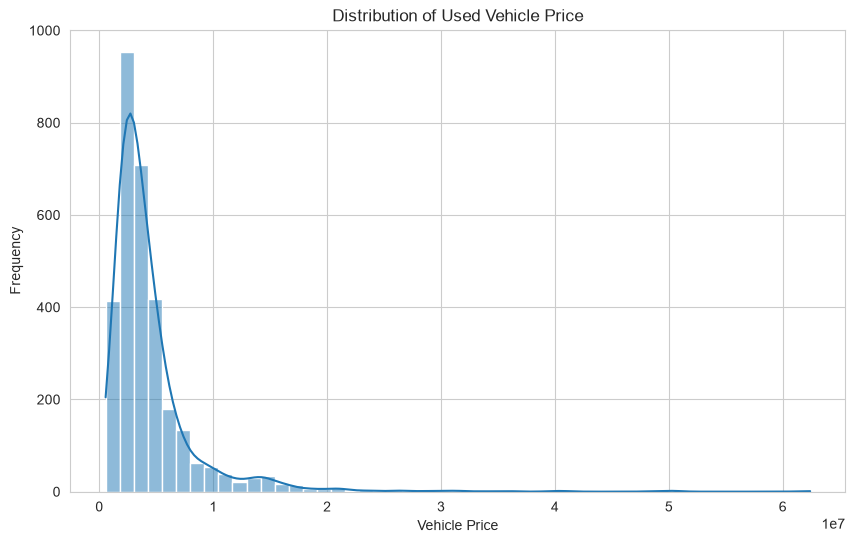

In [93]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df_clean["price"], 
    bins=50,
    kde=True
)

plt.title("Distribution of Used Vehicle Price")
plt.xlabel("Vehicle Price")
plt.ylabel("Frequency")

plt.show()

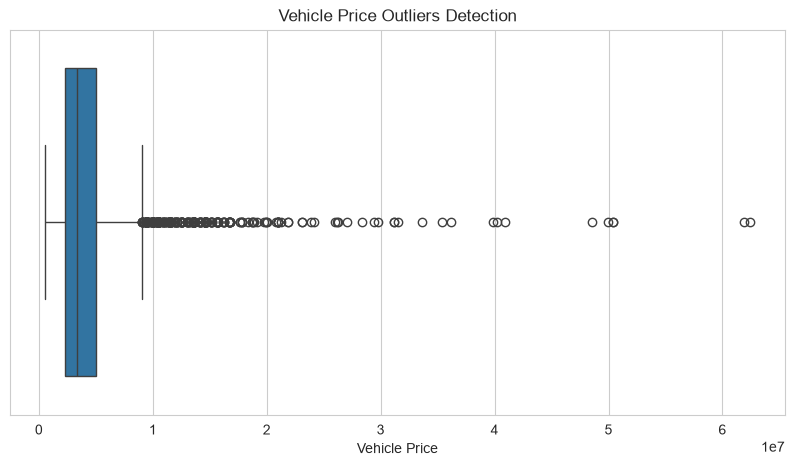

In [94]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    x=df_clean["price"]
)

plt.title("Vehicle Price Outliers Detection")
plt.xlabel("Vehicle Price")

plt.show()

**Calculate IQR**

In [95]:
# calculate Q1 and Q3
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)

# calculate IQR
IQR = Q3 - Q1

# calculate outlier boundarier
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Boundary:", lower_bound)
print("Upper Boundary:", upper_bound)



Q1: 2310000.0
Q3: 4992000.0
IQR: 2682000.0
Lower Boundary: -1713000.0
Upper Boundary: 9015000.0


**Identify outlier**

In [96]:
# Extract outliers
price_outliers = df_clean[
    (df_clean["price"] < lower_bound) |
    (df_clean["price"] > upper_bound)
]

print("Number of price outliers:", len(price_outliers))
print("Percentage pf price outlier:",
      round((len(price_outliers) / len(df_clean)) * 100, 2), "%")


Number of price outliers: 260
Percentage pf price outlier: 8.33 %


**Inspect the expensive vehicles**

In [97]:
price_outliers.sort_values(
    by="price",
    ascending=True
).head(20)

,car_id,price,fuel type,gear type,Make,Model,Year of manufacture,Colour,Condition,Mileage,Engine Size,Selling Condition,Bought Condition,car,Trim,Drivetrain,Seats,Number of Cylinders,Horse Power,Registered city,Engine Size Original,Vehicle Age,Mileage per year,Make_Model
117,65dOwu6ssrc50KbAeIq0KlcM,9030000,Petrol,Automatic,Mercedes-Benz,M Class,2012,Silver,Nigerian Used,152145.0,3500.0,Registered,Imported,Suv,ML 350 4Matic,All Wheel,5.0,6.0,302.0,Lagos,3500.0,14,10867.500000,Mercedes-BenzM Class
375,7y81VApjnNPMXhhgbXEbJRtQ,9048000,Petrol,Automatic,Mercedes-Benz,Glk-Class,2011,Black,Foreign Used,138800.0,3500.0,Imported,Imported,Suv,350 4MATIC,All Wheel,5.0,6.0,268.0,Unknown,3500.0,15,9253.333333,Mercedes-BenzGlk-Class
1996,84s8WOv59HDS8Se74XB7MpK6,9048000,Petrol,Automatic,Toyota,Venza,2011,Silver,Foreign Used,78411.0,3500.0,Imported,Imported,Suv,unknown,Unknown,NaN,NaN,NaN,Unknown,3500.0,15,5227.400000,ToyotaVenza
41,hI2ES3wPs918udEVtrFGu6WX,9048000,Petrol,Automatic,Toyota,Venza,2012,Silver,Foreign Used,125117.0,2700.0,Imported,Imported,Suv,unknown,Unknown,NaN,NaN,NaN,Unknown,2700.0,14,8936.928571,ToyotaVenza
1449,BRTMN64WUm9fVCZrY6P5z9bt,9135000,Petrol,Automatic,Toyota,Corolla,2019,Black,Nigerian Used,30411.0,1800.0,Registered,Brand New,Unknown,unknown,Unknown,NaN,NaN,NaN,Unknown,1800.0,7,4344.428571,ToyotaCorolla
15,8wBhIzD8AlTUaM3AaCrS4jvN,9135000,Petrol,Automatic,Toyota,Hiace,2011,Silver,Foreign Used,31234.0,2700.0,Imported,Imported,Unknown,unknown,Unknown,NaN,NaN,NaN,Unknown,2700.0,15,2082.266667,ToyotaHiace
302,51M40q6Sa5xjMfGSYqnaYe1E,9187500,Petrol,Automatic,Lexus,Rx 350,2010,Silver,Foreign Used,209153.0,3500.0,Imported,Imported,Suv,unknown,Unknown,NaN,NaN,NaN,Unknown,3500.0,16,13072.062500,LexusRx 350
2122,pWX0g1aeax3XBOx4MGnM7p,9240000,Petrol,Automatic,Lexus,Rx 350,2010,Black,Foreign Used,183905.0,3500.0,Imported,Imported,Suv,unknown,Unknown,NaN,NaN,NaN,Unknown,3500.0,16,11494.062500,LexusRx 350
321,ypg26CuaxI3AHo1vkEYXRvQc,9360000,Petrol,Automatic,Lexus,Rx 350,2010,Black,Nigerian Used,299715.0,3500.0,Registered,Registered,Suv,unknown,Unknown,NaN,NaN,NaN,Lagos,3500.0,16,18732.187500,LexusRx 350
1239,jGxvOBy0An6aJ3KlLGkNflie,9360000,Petrol,Automatic,Toyota,Venza,2010,Brown,Foreign Used,212735.0,3500.0,Imported,Imported,Suv,unknown,Unknown,NaN,NaN,NaN,Unknown,3500.0,16,13295.937500,ToyotaVenza


**Investigate price distribution using log transformation**

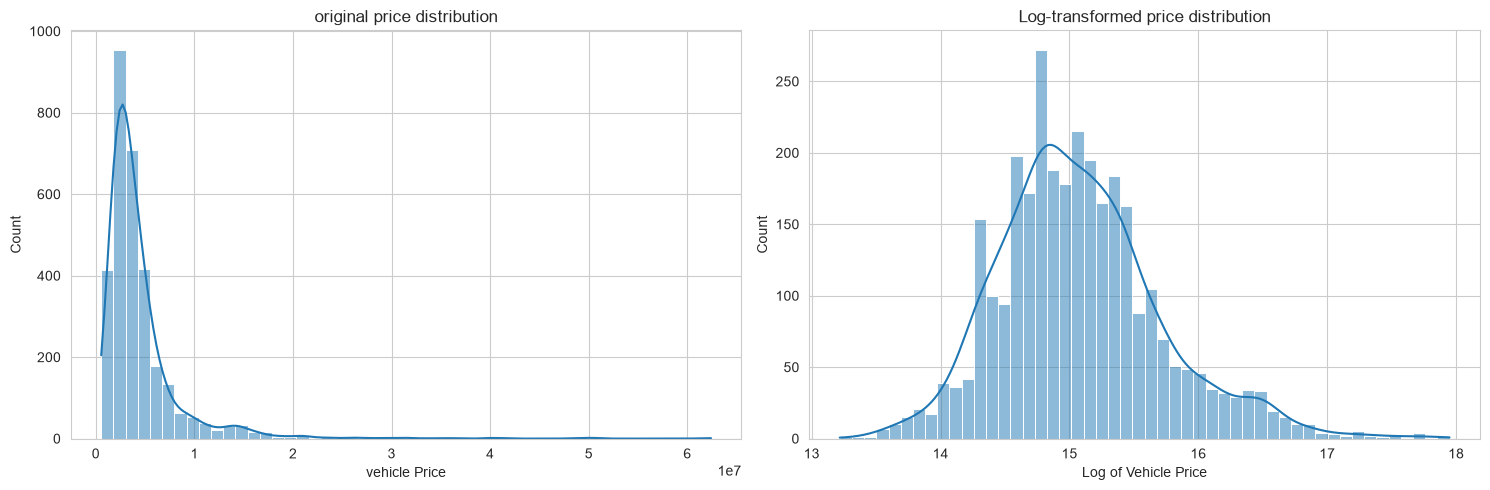

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# original price distribution
sns.histplot(
    df_clean["price"],
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("original price distribution")
axes[0].set_xlabel("vehicle Price")

# log-transformed price distribution
sns.histplot(
    np.log1p(df_clean["price"]),
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Log-transformed price distribution")
axes[1].set_xlabel("Log of Vehicle Price")

plt.tight_layout()
plt.show()

In [99]:
# calculate median price for each manufacturer
make_prices = (df_clean.groupby("Make")["price"].median().sort_values(ascending=True))

# display the top 15 manufacturer
make_prices.head(15)

Make
Dacia              735000.0
Other             1470000.0
Self Contained    1470000.0
Buick             1575000.0
Jac               1575000.0
Peugeot           1753750.0
Renault           1785000.0
Citroen           1995000.0
Seat              2100000.0
Opel              2152500.0
Volkswagen        2227500.0
Honda             2310000.0
Saturn            2467500.0
Ssangyong         2467500.0
Nissan            2520000.0
Name: price, dtype: float64

**Visualize manufacture prices**

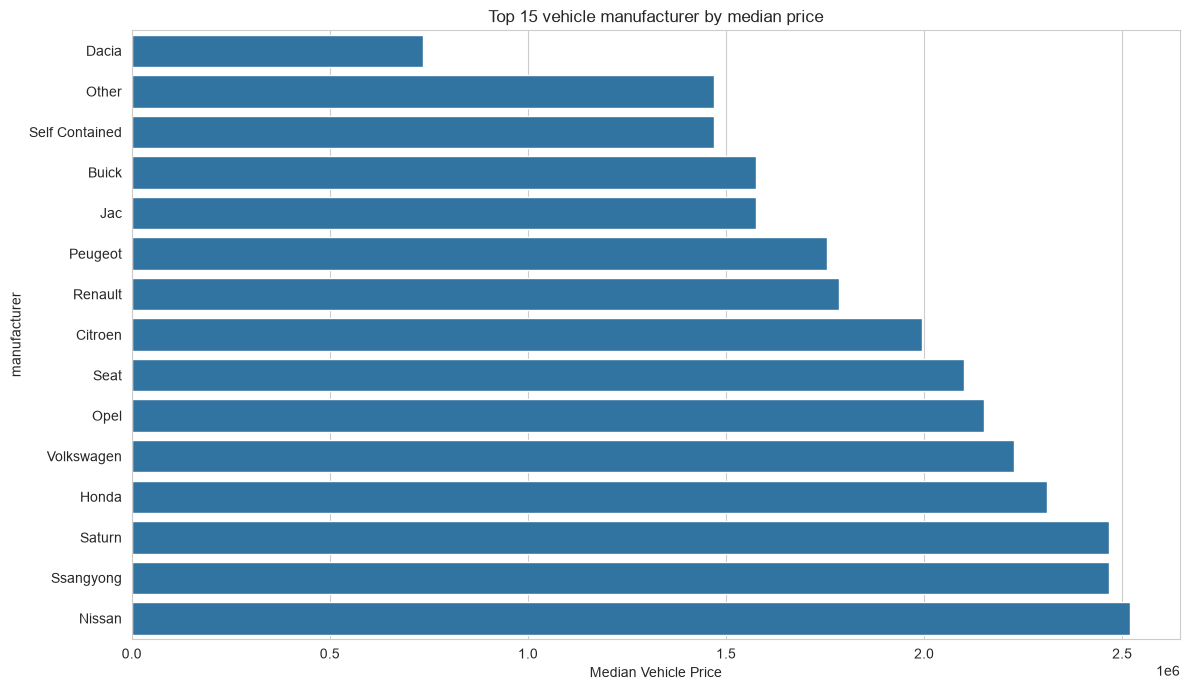

In [100]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=make_prices.head(15).values,
    y=make_prices.head(15).index
)
plt.title("Top 15 vehicle manufacturer by median price")
plt.xlabel("Median Vehicle Price")
plt.ylabel("manufacturer")

plt.tight_layout()
plt.show()

**Vehicle model VS price**

In [101]:
# find the 15 most frequently listed vehicle models
top_models = df_clean["Model"].value_counts().head(15).index

# feature dataset
model_data = df_clean[df_clean["Model"].isin(top_models)]

# calculate median price
model_prices = (model_data.groupby("Model")["price"].median().sort_values(ascending=False))

model_prices

Model
Rx 350        7350000.0
M Class       6240000.0
Venza         6032000.0
Highlander    5000000.0
C300          4680000.0
Es            3900000.0
Sonata        3885000.0
Rav4          3762000.0
Edge          3640000.0
Pilot         3255000.0
Camry         3120000.0
Sienna        3120000.0
Mdx           2995000.0
Corolla       2808000.0
Accord        2100000.0
Name: price, dtype: float64

**Visualize model prices**

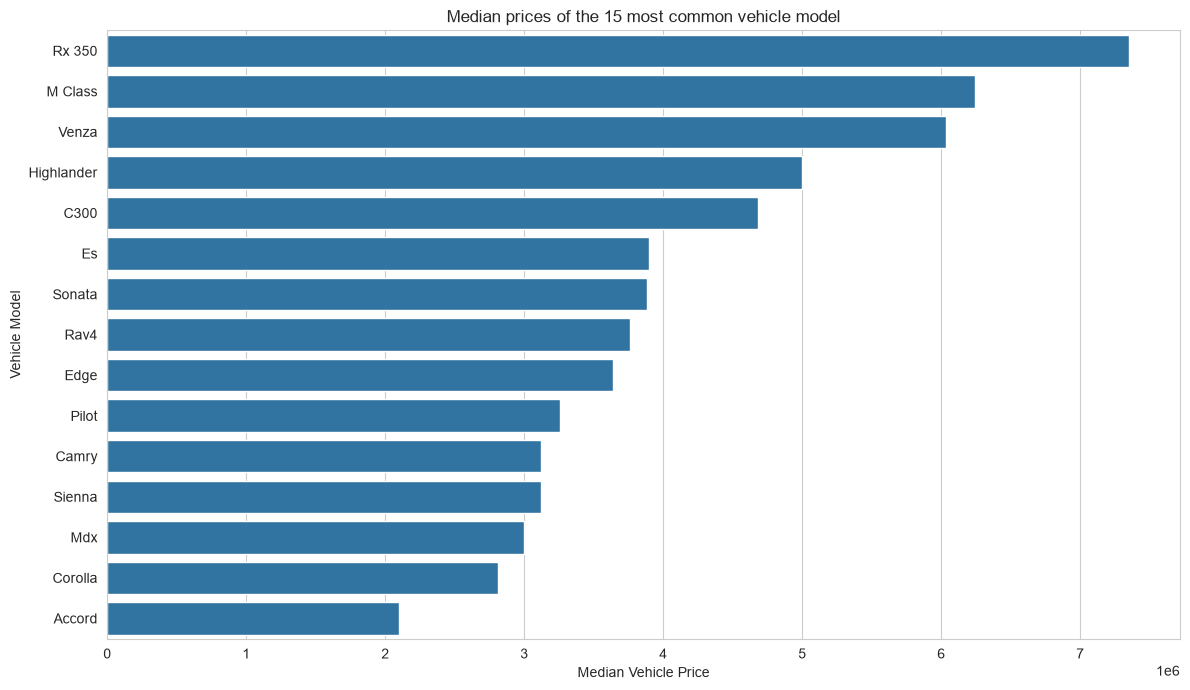

In [102]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=model_prices.values,
    y=model_prices.index
)

plt.title("Median prices of the 15 most common vehicle model")
plt.xlabel("Median Vehicle Price")
plt.ylabel("Vehicle Model")

plt.tight_layout()
plt.show()

In [103]:
year_prices = (df_clean.groupby("Year of manufacture")["price"].median().sort_values(ascending=False))

year_prices

Year of manufacture
2021    21900000.0
2022    19110000.0
2020    17850000.0
2018    15152500.0
2019    13012500.0
2016     9450000.0
2015     8882500.0
2017     7820000.0
2014     5720000.0
2013     5565000.0
2012     4807000.0
2011     4336500.0
2010     4200000.0
2009     3640000.0
2008     3150000.0
2007     3120000.0
2005     2600000.0
2006     2600000.0
2004     2200000.0
2003     2080000.0
1979     1890000.0
2002     1881000.0
2001     1768000.0
1995     1567500.0
1999     1567500.0
2000     1511525.0
1996     1365000.0
1998     1352000.0
1997     1265000.0
1994     1050000.0
1992      735000.0
Name: price, dtype: float64

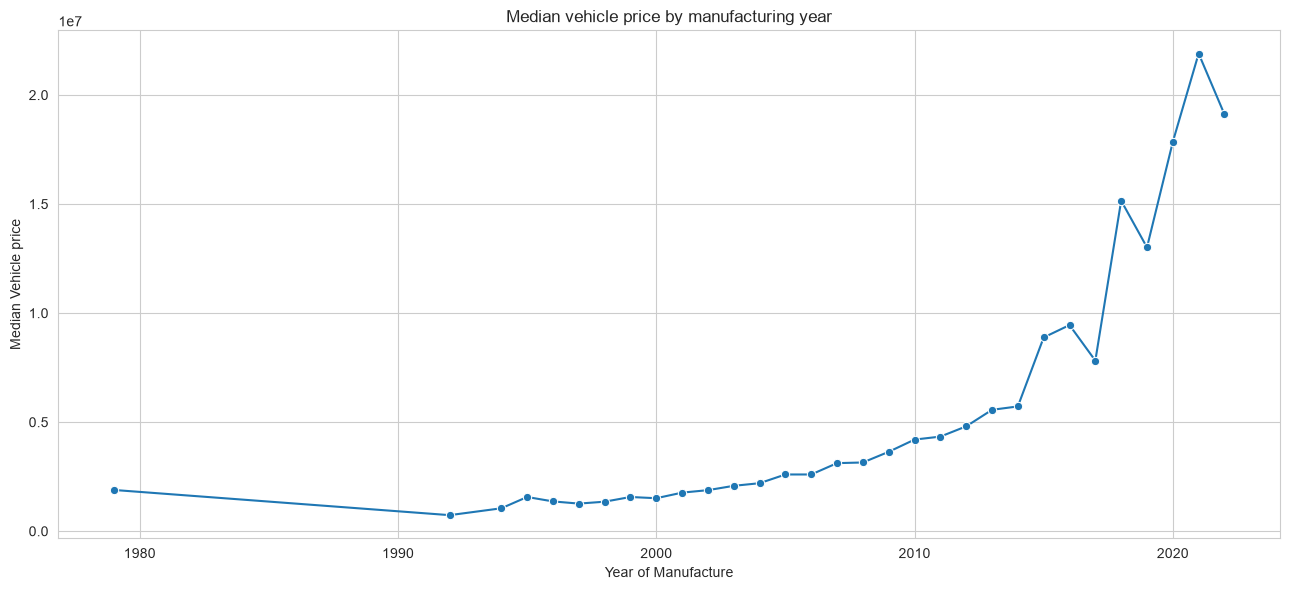

In [104]:
year_prices = (
    df_clean.groupby("Year of manufacture")["price"]
    .median()
    .sort_index()
)
plt.figure(figsize=(13, 6))
sns.lineplot(
    x=year_prices.index,
    y=year_prices.values,
    marker="o"
)

plt.title("Median vehicle price by manufacturing year")
plt.xlabel("Year of Manufacture")
plt.ylabel("Median Vehicle price")

plt.tight_layout()
plt.show()
               

**Mileage VS vehicle price**

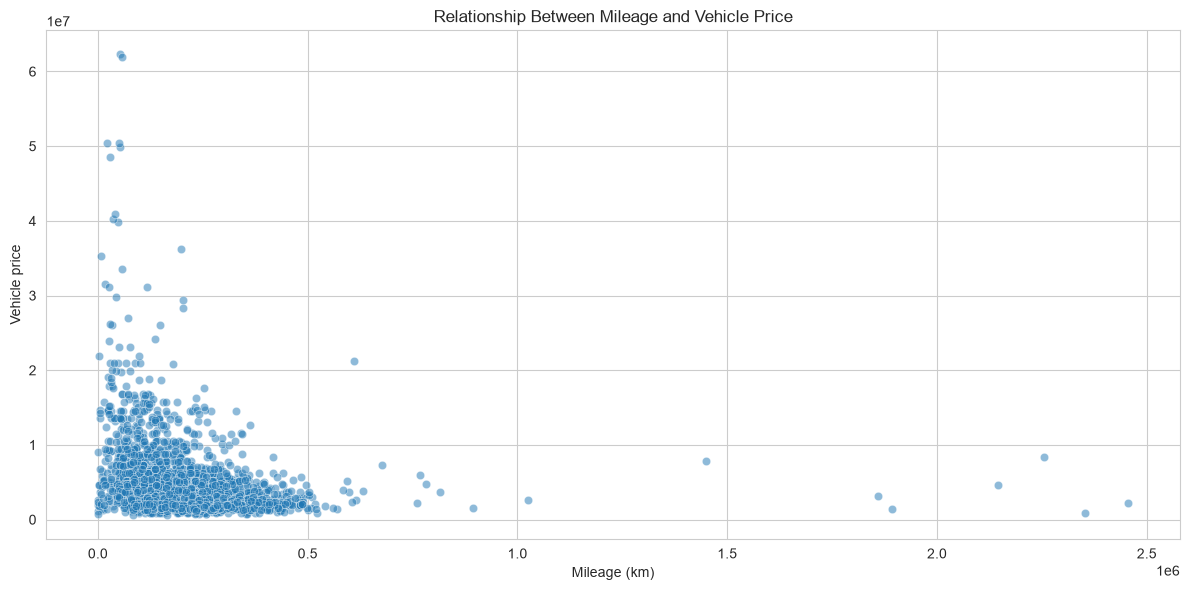

In [105]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_clean,
    x="Mileage",
    y="price",
    alpha=0.5
)
plt.title("Relationship Between Mileage and Vehicle Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Vehicle price")

plt.tight_layout()
plt.show()


**Calculate correlation**

In [106]:
mileage_correlation = df_clean[["Mileage", "price"]].corr()
mileage_correlation

,Mileage,price
Mileage,1.00000,-0.21152
price,-0.21152,1.00000


**Engine size VS vehicle price**

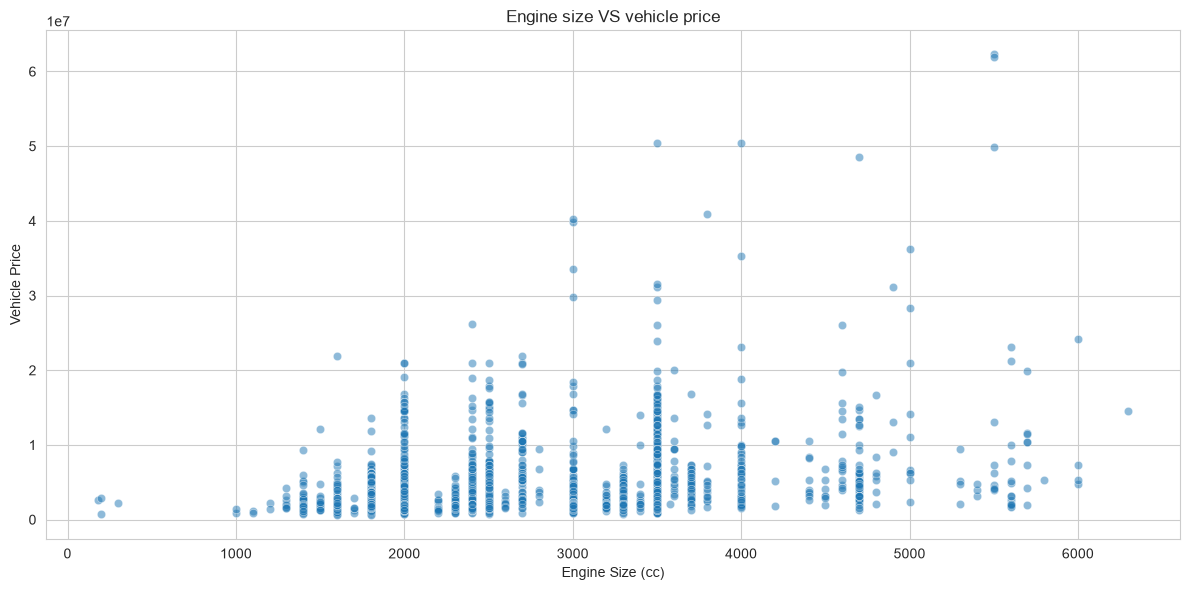

In [107]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_clean,
    x="Engine Size",
    y="price",
    alpha=0.5
)

plt.title("Engine size VS vehicle price")
plt.xlabel("Engine Size (cc)")
plt.ylabel("Vehicle Price")

plt.tight_layout()
plt.show()

In [108]:
df_clean["Engine Size"].describe()

count    2986.000000
mean     2784.313463
std       861.220754
min       180.000000
25%      2000.000000
50%      2500.000000
75%      3500.000000
max      6300.000000
Name: Engine Size, dtype: float64

**Vehicle condition VS price**

In [109]:
condition_prices = (df_clean.groupby("Condition")["price"].median().sort_values(ascending=False))
condition_prices

Condition
Brand New        6010000.0
Foreign Used     4937500.0
Nigerian Used    2835000.0
Name: price, dtype: float64

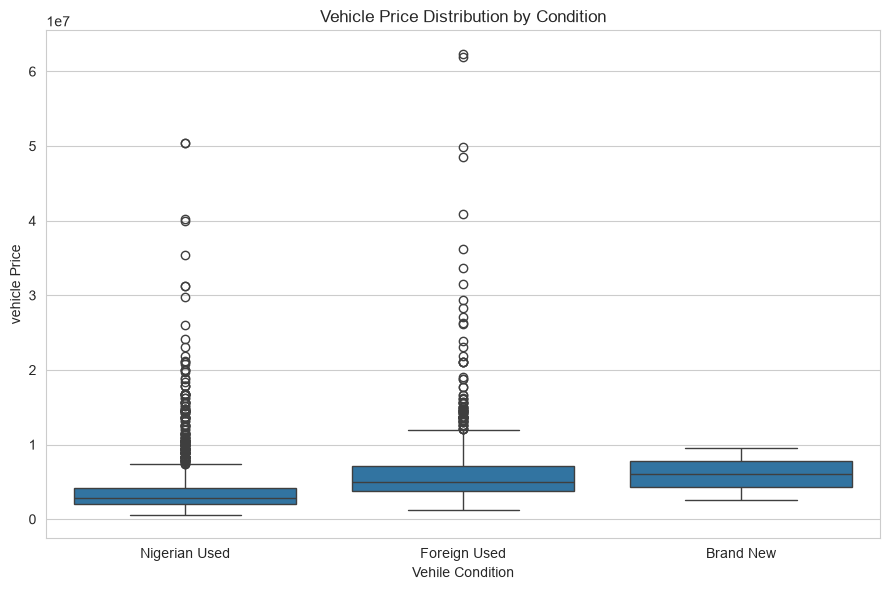

In [110]:
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df_clean,
    x="Condition",
    y="price"
)

plt.title("Vehicle Price Distribution by Condition")
plt.xlabel("Vehile Condition")
plt.ylabel("vehicle Price")
plt.tight_layout()
plt.show()

**Numerical feature correlation**

In [111]:
# select numerical column
numeric_df = df_clean.select_dtypes(include=np.number)

# calculate correlation matrix
correlation_matrix = numeric_df.corr()

correlation_matrix

,price,Year of manufacture,Mileage,Engine Size,Seats,Number of Cylinders,Horse Power,Engine Size Original,Vehicle Age,Mileage per year
price,1.000000,0.547790,-0.211520,0.296818,0.088977,0.197112,0.402149,0.296818,-0.547790,-0.065463
Year of manufacture,0.547790,1.000000,-0.323493,0.017047,-0.032272,-0.094710,0.217742,0.017047,-1.000000,-0.021966
Mileage,-0.211520,-0.323493,1.000000,-0.012842,-0.012415,0.011307,-0.050660,-0.012842,0.323493,0.925788
Engine Size,0.296818,0.017047,-0.012842,1.000000,0.330924,0.837299,0.834657,1.000000,-0.017047,-0.003610
Seats,0.088977,-0.032272,-0.012415,0.330924,1.000000,0.366300,0.312688,0.330924,0.032272,-0.028970
Number of Cylinders,0.197112,-0.094710,0.011307,0.837299,0.366300,1.000000,0.837644,0.837299,0.094710,-0.015618
Horse Power,0.402149,0.217742,-0.050660,0.834657,0.312688,0.837644,1.000000,0.834657,-0.217742,0.007616
Engine Size Original,0.296818,0.017047,-0.012842,1.000000,0.330924,0.837299,0.834657,1.000000,-0.017047,-0.003610
Vehicle Age,-0.547790,-1.000000,0.323493,-0.017047,0.032272,0.094710,-0.217742,-0.017047,1.000000,0.021966
Mileage per year,-0.065463,-0.021966,0.925788,-0.003610,-0.028970,-0.015618,0.007616,-0.003610,0.021966,1.000000


**Visualize the correlation matrix**

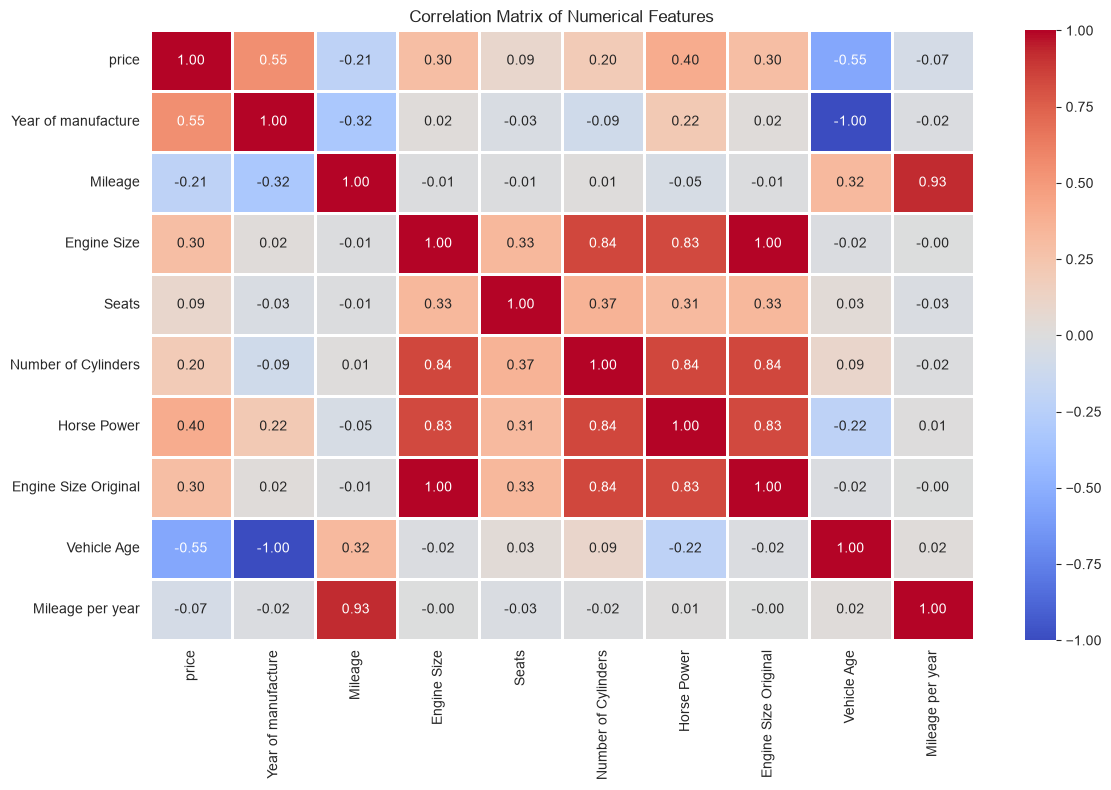

In [112]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=1
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

**Data cleaning and feature engineering**

In [113]:
# create a working copy
df_model = df_clean.copy()
print("Working Dataset Shape:", df_model.shape)

Working Dataset Shape: (3120, 24)


**Inspect missing values**

In [114]:
missing = pd.DataFrame({
    "Mising_counts": df_model.isnull().sum(),
    "Missing_percentage": (df_model.isnull().sum() / len(df_model)) * 100
})

missing = missing.sort_values(
    by="Missing_percentage",
    ascending=False
)
missing

,Mising_counts,Missing_percentage
Horse Power,2485,79.647436
Seats,2458,78.782051
Number of Cylinders,2425,77.724359
Engine Size,134,4.294872
Engine Size Original,134,4.294872
Mileage,51,1.634615
Mileage per year,51,1.634615
car_id,0,0.000000
Colour,0,0.000000
Year of manufacture,0,0.000000


In [115]:
# inspect unsual engine size
engine_anomalies = df_model[
    (df_model["Engine Size"] > 10000) |
    (df_model["Engine Size"] <=0)
]
print("Unusual engine-size records:", len(engine_anomalies))

engine_anomalies[
        ["Make", "Model", "Engine Size", "price"]
].head(20)

Unusual engine-size records: 0


,Make,Model,Engine Size,price


**Adding implausible engine types**

In [116]:
# copy original engine values for auditing
df_model["Engine Size Original"] = df_model["Engine Size"]

# replace implausible engine types with NaN
invalid_engine = (
    (df_model["Engine Size"] > 10000) |
    (df_model["Engine Size"] <= 0)
)
df_model.loc[invalid_engine, "Engine Size"] = np.nan

print("Engine-size values marked missing:", invalid_engine.sum())

print("Remaining invalid_engine sizes:", ((df_model["Engine Size"] > 10000) | (df_model["Engine Size"] <=0)).sum())
                  

Engine-size values marked missing: 0
Remaining invalid_engine sizes: 0


**Clean categorical features**

In [117]:
# Identify categorical columns
categoric_df = df_model.select_dtypes(include=["object", "string"]).columns

# standardize text values
for col in categoric_df:
    df_model[col] = (
        df_model[col]
        .str.strip()
        .replace("",np.nan)
    )
# standardize selected columns

columns_to_standardize = [
    "Make",
    "Model",
    "Colour",
    "Condition",
    "fuel type",
    "gear type",
    "Selling Condition",
    "Bought Condition",
    "car",
    "Drivetrain",
    "Registered city"
]
for col in columns_to_standardize:
    df_model[col] = df_model[col].str.title()
print("Categorical values standardize successfully!")

Categorical values standardize successfully!


**Handling missing categorical values**

In [118]:
categoric_df = df_model.select_dtypes(
    include=["object", "string"]
).columns
for col in categoric_df:
    df_model[col] = df_model[col].fillna("unknown")

print("Missing categorical values handled")

Missing categorical values handled


**Create a new features (Featuring Engineering)**

In [119]:
CURRENT_YEAR = 2026
df_model["Vehicle Age"] = (
    CURRENT_YEAR - df_model["Year of manufacture"]
)
df_model[[
    "Year of manufacture",
    "Vehicle Age"
]].head()

,Year of manufacture,Vehicle Age
0,2004,22
1,2007,19
2,2012,14
3,2012,14
4,2013,13


**Creating Mileage Per Year**

In [120]:
df_model["Mileage per year"] = (
    df_model["Mileage"] /
    df_model["Vehicle Age"].clip(lower=1)
)
df_model[[
    "Mileage",
    "Vehicle Age",
    "Mileage per year"
]].head()

,Mileage,Vehicle Age,Mileage per year
0,251732.0,22,11442.363636
1,224589.0,19,11820.473684
2,111334.0,14,7952.428571
3,72682.0,14,5191.571429
4,92118.0,13,7086.000000


**Combine manufacturer and model**

In [121]:
df_model["Make_Model"] = (
    df_model["Make"] + "" + df_model["Model"]
)
df_model[[
    "Make",
    "Model",
    "Make_Model"
]].head()

,Make,Model,Make_Model
0,Toyota,Corolla,ToyotaCorolla
1,Acura,Mdx,AcuraMdx
2,Acura,Tl,AcuraTl
3,Land Rover,Range Rover,Land RoverRange Rover
4,Ford,Edge,FordEdge


**Inspect the cleaned dataset**

In [122]:
print("Final working dataset shape:", df_model.shape)

df_model.head()

Final working dataset shape: (3120, 24)


,car_id,price,fuel type,gear type,Make,Model,Year of manufacture,Colour,Condition,Mileage,Engine Size,Selling Condition,Bought Condition,car,Trim,Drivetrain,Seats,Number of Cylinders,Horse Power,Registered city,Engine Size Original,Vehicle Age,Mileage per year,Make_Model
0,icwAaDOmX573WiRRnLFPT237,2812500,Petrol,Automatic,Toyota,Corolla,2004,Silver,Nigerian Used,251732.0,1800.0,Registered,Registered,Unknown,unknown,Unknown,NaN,NaN,NaN,Unknown,1800.0,22,11442.363636,ToyotaCorolla
1,ByZ3NlPy2x0arAIyrKazClUS,5000000,Petrol,Automatic,Acura,Mdx,2007,Green,Foreign Used,224589.0,3700.0,Imported,Imported,Suv,unknown,Unknown,NaN,NaN,NaN,Unknown,3700.0,19,11820.473684,AcuraMdx
2,2zG6Mh3kwyoTvWoeKHkV1oFH,7592000,Petrol,Automatic,Acura,Tl,2012,White,Foreign Used,111334.0,3500.0,Imported,Imported,Sedan,SH-AWD Automatic Tech Package,All Wheel,5.0,6.0,309.0,Unknown,3500.0,14,7952.428571,AcuraTl
3,7APLHOPlI93qsYK0ST4D4wB2,9880000,Petrol,Automatic,Land Rover,Range Rover,2012,Gray,Nigerian Used,72682.0,4000.0,Registered,Imported,Suv,unknown,Unknown,NaN,NaN,NaN,Unknown,4000.0,14,5191.571429,Land RoverRange Rover
4,zIrIDPJLd46eRQf9JFacc0e,4160000,Petrol,Automatic,Ford,Edge,2013,Gray,Nigerian Used,92118.0,3500.0,Registered,Registered,Suv,unknown,Unknown,NaN,NaN,NaN,Lagos,3500.0,13,7086.000000,FordEdge


**Check remaining missing values**

In [123]:
remaining_missing = df_model.isnull().sum()
remaining_missing[remaining_missing > 0]

CLEANED_PATH = r"C:\Users\HomePC\used_car_valuation\data\car_prices.csv"
df_model.to_csv(CLEANED_PATH, index=False)

print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully


In [124]:
# Define target variable
y = df_model["price"]

# Define input features
x = df_model.drop(columns=["price", "car_id", "Engine Size Original"], errors="ignore")

print("Feature shape:", x.shape)
print("Target shape:", y.shape)

Feature shape: (3120, 21)
Target shape: (3120,)


**Identify categorical features**

In [125]:
# identify categorical feature

categorical_feature = x.select_dtypes(include=["object", "string"]).columns.tolist()
print("Categorical Features:")
print(categorical_feature)                                      
                                      

Categorical Features:
['fuel type', 'gear type', 'Make', 'Model', 'Colour', 'Condition', 'Selling Condition', 'Bought Condition', 'car', 'Trim', 'Drivetrain', 'Registered city', 'Make_Model']


**Validate the Dataset**

In [126]:
# check target variable
print("Missing price:", y.isnull().sum())
print("Zero or negative prices:", (y <= 0).sum())

# check missing categorical values
print("Missing categorical values:", x[categorical_feature].isnull().sum().sum())

Missing price: 0
Zero or negative prices: 0
Missing categorical values: 0


In [127]:
# Keep only valid target records
valid_target = y.notna() & (y > 0)

X = x.loc[valid_target].copy()
y = y.loc[valid_target].copy()

# Handle missing categorical values
for col in categorical_feature:
    x[col] = X[col].fillna("Unknown").astype(str)

print("Validated features:", X.shape)
print("Validated target:", y.shape)

Validated features: (3120, 21)
Validated target: (3120,)


**Split the data**

In [128]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation, 15% testing
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Training data:", X_train.shape)
print("Validation data:", X_valid.shape)
print("Testing data:", X_test.shape)

Training data: (2184, 21)
Validation data: (468, 21)
Testing data: (468, 21)


**Verify the split**

In [129]:
print("Total records:",
      len(X_train) + len(X_valid) + len(X_test))

print("Training records:", len(X_train))
print("Validation records:", len(X_valid))
print("Testing records:", len(X_test))

Total records: 3120
Training records: 2184
Validation records: 468
Testing records: 468


**CatBoost model Development**

In [130]:
from catboost import CatBoostRegressor
print("Catboost imported succesfully")

Catboost imported succesfully


**Build the first model - Median price prediction**

In [131]:
q50_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.03,
    depth=8,
    loss_function="Quantile:alpha=0.5",
    eval_metric="Quantile:alpha=0.5",
    random_seed=42,
    verbose=100
)
#Train the model
q50_model.fit(
    X_train,
    y_train,
    cat_features=categorical_feature,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100,
    use_best_model=True
)
print("Median price model trained successfully!")

0:	learn: 1117256.5455240	test: 1006155.1126108	best: 1006155.1126108 (0)	total: 108ms	remaining: 1m 48s
100:	learn: 524939.1274951	test: 520322.4880439	best: 520322.4880439 (100)	total: 9.15s	remaining: 1m 21s
200:	learn: 417105.2437195	test: 495102.6766162	best: 492640.3253500 (162)	total: 19s	remaining: 1m 15s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 492640.3253
bestIteration = 162

Shrink model to first 163 iterations.
Median price model trained successfully!


**Train the lower price model**

In [132]:
def train_quantile_model(alpha):
    model = CatBoostRegressor(
        iterations=2000,
        learning_rate=0.03,
        depth=8,
        loss_function=f"Quantile:alpha={alpha}",
        eval_metric=f"Quantile:alpha={alpha}",
        random_seed=42,
        verbose=100
    )
    model.fit(
        X_train,
        y_train,
        cat_features=categorical_feature,
        eval_set=(X_valid, y_valid),
        early_stopping_rounds=100,
        use_best_model=True
    )

    return model
    

In [133]:
# train lower price model
q10_model = train_quantile_model(0.10)

# train upper price model
q90_model = train_quantile_model(0.90)

print("Q10 and Q90 model trained successfully!")

0:	learn: 316060.0522252	test: 285704.7479244	best: 285704.7479244 (0)	total: 70.7ms	remaining: 2m 21s
100:	learn: 204549.1287624	test: 206346.3120304	best: 206346.3120304 (100)	total: 10.2s	remaining: 3m 12s
200:	learn: 172362.1735430	test: 195407.9930283	best: 195085.0826308 (192)	total: 19.5s	remaining: 2m 54s
300:	learn: 159319.7340272	test: 195453.5291234	best: 193896.2524801 (241)	total: 29.1s	remaining: 2m 44s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 193896.2525
bestIteration = 241

Shrink model to first 242 iterations.
0:	learn: 983036.4298593	test: 819376.0381700	best: 819376.0381700 (0)	total: 49.7ms	remaining: 1m 39s
100:	learn: 250521.6291524	test: 340628.0060515	best: 340628.0060515 (100)	total: 8.93s	remaining: 2m 47s
200:	learn: 196974.3616266	test: 330647.0914793	best: 330612.7770927 (191)	total: 18.3s	remaining: 2m 43s
300:	learn: 174366.0303108	test: 328059.0968180	best: 327275.7238360 (289)	total: 29.5s	remaining: 2m 46s
Stopped by overfitti

In [134]:
import catboost
print("CatBoost version:", catboost.__version__)

CatBoost version: 1.2.10


In [135]:
print("python environment:", __import__("sys").executable)

python environment: C:\Users\HomePC\AppData\Local\Programs\Python\Python314\python.exe


In [136]:
%pip install --upgrade catboost

Note: you may need to restart the kernel to use updated packages.


In [137]:
quantil_model = {
    0.10: q10_model,
    0.50: q50_model,
    0.90: q90_model
}
print("All three quantile model are ready!")

All three quantile model are ready!


**Generate predictions**

In [138]:
# generate predictions
q10_prediction = q10_model.predict(X_test)

q50_prediction = q50_model.predict(X_test)

q90_prediction = q90_model.predict(X_test)

print("All predictions generated successfully!")

All predictions generated successfully!


**Create a prediction DataFrame**

In [139]:
prediction_df = pd.DataFrame({
    "Actual price": y_test.values,
    "Lower price (Q10)": q10_prediction,
    "Fair market price (Q50)": q50_prediction,
    "Upper price (Q90)": q90_prediction
})

prediction_df.head(50)

,Actual price,Lower price (Q10),Fair market price (Q50),Upper price (Q90)
0,18375000,5.550073e+06,1.063397e+07,2.025281e+07
1,1785000,2.482834e+06,2.822977e+06,3.834133e+06
2,9450000,5.392567e+06,1.226432e+07,1.411422e+07
3,4368000,3.625666e+06,3.884595e+06,4.525442e+06
4,3591000,3.069135e+06,4.266568e+06,5.200740e+06
5,4368000,3.061620e+06,4.101833e+06,5.942956e+06
6,2625000,3.201588e+06,3.973159e+06,5.083271e+06
7,2100000,2.628750e+06,3.816203e+06,5.263867e+06
8,6760000,2.595432e+06,4.093131e+06,6.449382e+06
9,2310000,1.848644e+06,2.179318e+06,3.043122e+06


**Evaluate model performance**

In [140]:
# Actual prices
y_actual = y_test

# Median predicted prices
y_pred = q50_prediction

# Calculate metrics
mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

r2 = r2_score(y_actual, y_pred)

print("CATBOSST MODEL PERFORMANCE")
print("---------------------------")

print(f"MAE: N{mae:.2f}")
print(f"RMSE: N{rmse:.2f}")
print(f"r2_score: N{r2:.4f}")

CATBOSST MODEL PERFORMANCE
---------------------------
MAE: N1006816.49
RMSE: N1944254.09
r2_score: N0.7216


**Evaluate the prediction interval**

In [ ]:
# Calculate prediction interval coverage
coverage = np.mean(
    (y_actual.values >= q10_prediction) &
    (y_actual.values <= q90_prediction)
)
# Calculate average interval width
interval_width = np.mean(
    q90_prediction - q10_prediction
)

print("PREDICTION INTERVAL EVALUATION")
print("-------------------------------")
print(f"Coverage: {coverage:.2%}")
print(f"Average interval width: N{interval_width:.2f}")

**Visualize VS predicted prices**

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=y_actual,
    y=y_pred,
    alpha=0.5
)

plt.plot(
    [y_actual.min(), y_actual.max()],
    [y_actual.min(), y_actual.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Vehicle Prices")
plt.xlabel("Actual Vehicle Prices (N)")
plt.ylabel("Predicted Vehicle Prices (N)")

plt.tight_layout()
plt.show()

**Check for quantile crossing**

In [ ]:
crossing = (
    (q10_prediction > q50_prediction) |
    (q50_prediction > q90_prediction)
)

print("Number of crossing prediction:", crossing.sum())
print("Crossing percentage:", round(crossing.mean() * 100, 2), "%")


**Save the trained model**

In [ ]:
import joblib
from pathlib import Path

MODEL_DIR = Path(r"C:\Users\HomePC\used_car_valuation\model\models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(q10_model, MODEL_DIR / "catboost_q10.pkl")
joblib.dump(q50_model, MODEL_DIR / "catboost_q50.pkl")
joblib.dump(q90_model, MODEL_DIR / "catboost_q90.pkl")

print("All quantile model saved successfully!")